<a href="https://colab.research.google.com/github/ialipon/ENCH680PRJ/blob/main/PRJ_knn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project - KNN

**Objectives**

By the end of this session, we will be able to:

First Stage
- Use KNN modeling for classification.
- Prepare a research dataset for classification: clean it to exclude data that are to be excluded and turn Recovery% into desirable/undesirable labels
  - Predict Recovery% is desirable or undesirable for provided data input variable.
- Train a K-Nearest Neighbors (KNN) classifier with scikit-learn and evaluate it with test accuracy
- Tune KNN hyperparameters (`n_neighbors`, `weights`) by comparing test accuracy across values of `k`
- Explain why KNN needs feature scaling, and compare models trained with and without `StandardScaler`

Second stage:
- Use KNN modeling for regression


## 1. Import python packages: matplotlib, pandas, numpy

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## 2. Read CO2 capture data from xlsx file

In [3]:
data_file_path = "https://github.com/ialipon/ENCH680PRJ/raw/main/Dataset.xlsx"
Rec_data = pd.read_excel(data_file_path)

## 3. Prepare Dataset

In the dataset, we can see that there are eight input columns and three output columns where the output columns are "Recovery%", "SEC", and "CO2 Purity". All these three output columns will be excluded as input variable.

For the KNN classification, we will use Recovery% as the target output where:
- Recovery ≥ 80%: Desirable.
- Recovery below 80%: Not Desirable.
This will evaluate whether the operating parameters can identify desirable conditions.

For the KNN regression, we will use the desired operating parameters to evaluate SEC prediction.


In [4]:
print(Rec_data.head(10))

   Fluegas CO2 mol%  Fluegas Flow (kg/h)  Lean Solvent Flow (kg/h)  \
0               2.0              1500000             799999.978656   
1               2.5              1500000             800000.056029   
2               3.0              1500000             800000.046691   
3               3.5              1500000             800000.030682   
4               4.0              1500000             800000.038687   
5               4.5              1500000             800000.028014   
6               2.0              3100000             800000.010672   
7               2.5              3100000             799999.997332   
8               3.0              3100000             800000.004002   
9               3.5              3100000             800000.000000   

   Lean Solvent Loading Amine type  Amine Conc (wt%)  Lean Solvent T (C)  \
0              0.549078        MEA         14.992197                  37   
1              0.684311        MEA         14.992198                  37   
2

## 4. Stage 1 - KNN Classification

Let's define and assign Desirable Recovery%
- Recovery ≥ 80%: Desirable.
- Recovery < 80%: Not Desirable.

In [5]:
# Create new classification column

Rec_data["Classification"] = np.where(
    Rec_data["Recovery%"] >= 80,
    "Desirable",
    "Not Desirable"
)

# Display the results
print(Rec_data.head(10))

# Save the updated dataset
Rec_data.to_excel("Dataset_with_Classification.xlsx", index=False)

   Fluegas CO2 mol%  Fluegas Flow (kg/h)  Lean Solvent Flow (kg/h)  \
0               2.0              1500000             799999.978656   
1               2.5              1500000             800000.056029   
2               3.0              1500000             800000.046691   
3               3.5              1500000             800000.030682   
4               4.0              1500000             800000.038687   
5               4.5              1500000             800000.028014   
6               2.0              3100000             800000.010672   
7               2.5              3100000             799999.997332   
8               3.0              3100000             800000.004002   
9               3.5              3100000             800000.000000   

   Lean Solvent Loading Amine type  Amine Conc (wt%)  Lean Solvent T (C)  \
0              0.549078        MEA         14.992197                  37   
1              0.684311        MEA         14.992198                  37   
2

## 5. Understand how the data looks like using scatter plots

- [Main reference for matplotlib point styling](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.scatter.html)
- [Color names you can use](https://matplotlib.org/stable/gallery/color/named_colors.html)
- [Marker shapes](https://matplotlib.org/stable/api/markers_api.html)
- [Color maps](https://matplotlib.org/stable/users/explain/colors/colormaps.html)

5.1 Fluegas CO2 mol% vs CO2 Recovery %

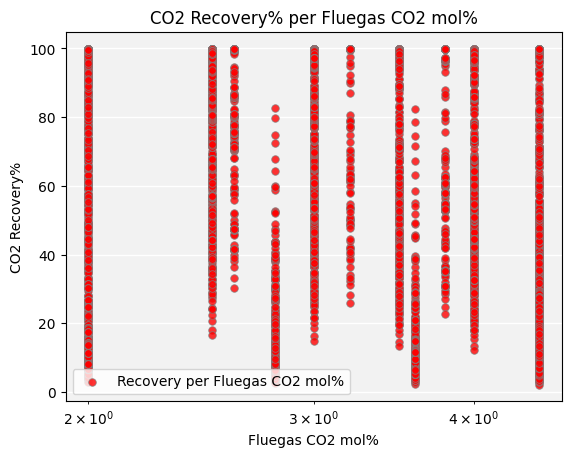

In [14]:
ax = Rec_data.plot.scatter(
    x="Fluegas CO2 mol%",
    y="Recovery%",
    title="CO2 Recovery% per Fluegas CO2 mol%",
    grid=True,
    logx=True,
    label="Recovery per Fluegas CO2 mol%",
    xlabel="Fluegas CO2 mol%",
    ylabel="CO2 Recovery%",
    marker="o",  # shape of the points
    c="red",  # color of the points
    s=30,  # size of the points
    edgecolor="grey",  # edge color of the points
    linewidth=0.6,  # edge line width of the points
    alpha=0.8,  # transparency of the points
)

ax.figure.set_facecolor("white")  # the whole figure (outside the axes)
ax.set_facecolor("#f2f2f2")  # the plotting area (inside the axes)

ax.grid(color="white", linewidth=1)
ax.set_axisbelow(True)

plt.show()

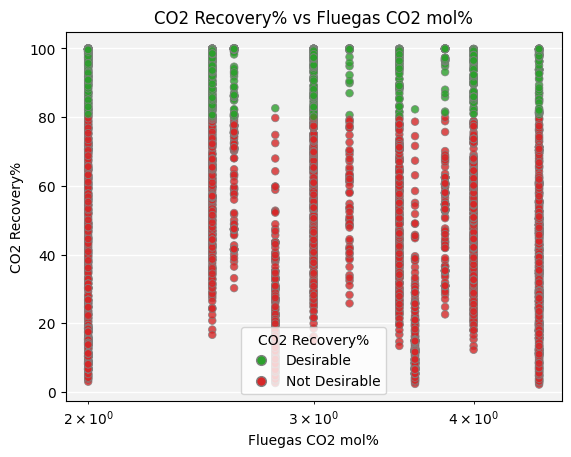

In [17]:
from matplotlib.lines import Line2D

# One color per Recovery% Classification label, used for both the points and the legend
label_colors = {"Desirable": "tab:green", "Not Desirable": "tab:red"}

ax = Rec_data.plot.scatter(
    x="Fluegas CO2 mol%",
    y="Recovery%",
    title="CO2 Recovery% vs Fluegas CO2 mol%",
    grid=True,
    logx=True,
    label="Recovery per Fluegas CO2 mol"
    xlabel="Fluegas CO2 mol%",
    ylabel="CO2 Recovery%",
    marker="o",  # shape of the points
    c=Rec_data["Classification"].map(label_colors),  # color of the points
    s=30,  # size of the points
    edgecolor="grey",  # edge color of the points
    linewidth=0.6,  # edge line width of the points
    alpha=0.8,  # transparency of the points
)

# Legend: one marker per label, drawn in the same color as the points
legend_handles = [
    Line2D(
        [],
        [],
        marker="o",
        linestyle="",
        markerfacecolor=color,
        markeredgecolor="grey",
        markersize=7,
        label=label,
    )
    for label, color in label_colors.items()
]
ax.legend(handles=legend_handles, title="CO2 Recovery%")

ax.figure.set_facecolor("white")  # the whole figure (outside the axes)
ax.set_facecolor("#f2f2f2")  # the plotting area (inside the axes)

ax.grid(color="white", linewidth=1)
ax.set_axisbelow(True)

plt.show()

5.2 Fluegas Flow

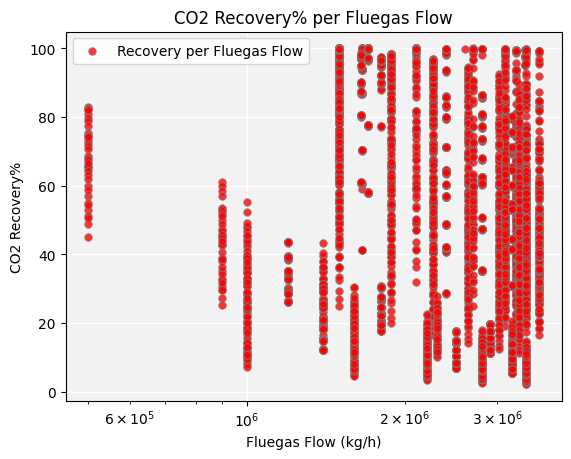

In [15]:
ax = Rec_data.plot.scatter(
    x="Fluegas Flow (kg/h)",
    y="Recovery%",
    title="CO2 Recovery% per Fluegas Flow",
    grid=True,
    logx=True,
    label="Recovery per Fluegas Flow",
    xlabel="Fluegas Flow (kg/h)",
    ylabel="CO2 Recovery%",
    marker="o",  # shape of the points
    c="red",  # color of the points
    s=30,  # size of the points
    edgecolor="grey",  # edge color of the points
    linewidth=0.6,  # edge line width of the points
    alpha=0.8,  # transparency of the points
)

ax.figure.set_facecolor("white")  # the whole figure (outside the axes)
ax.set_facecolor("#f2f2f2")  # the plotting area (inside the axes)

ax.grid(color="white", linewidth=1)
ax.set_axisbelow(True)

plt.show()

5.3 Lean Solvent Flow

In [ ]:
ax = Rec_data.plot.scatter(
    x="Fluegas Flow (kg/h)",
    y="Recovery%",
    title="CO2 Recovery% per Fluegas Flow",
    grid=True,
    logx=True,
    label="Recovery per Fluegas Flow",
    xlabel="Fluegas Flow (kg/h)",
    ylabel="CO2 Recovery%",
    marker="o",  # shape of the points
    c="red",  # color of the points
    s=30,  # size of the points
    edgecolor="grey",  # edge color of the points
    linewidth=0.6,  # edge line width of the points
    alpha=0.8,  # transparency of the points
)

ax.figure.set_facecolor("white")  # the whole figure (outside the axes)
ax.set_facecolor("#f2f2f2")  # the plotting area (inside the axes)

ax.grid(color="white", linewidth=1)
ax.set_axisbelow(True)

plt.show()

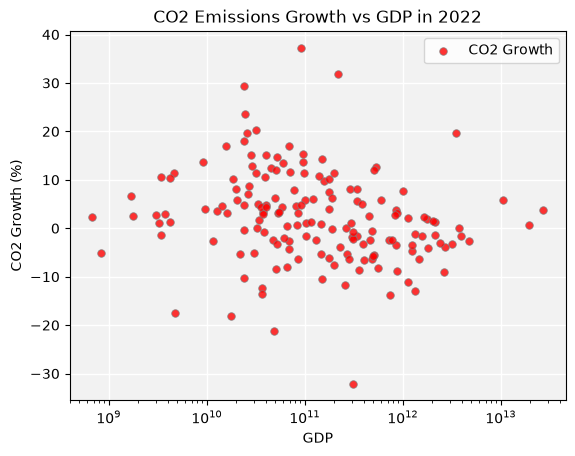

In [ ]:
ax = df_co2_2022_labeled.plot.scatter(
    x="gdp",
    y="co2_growth_prct",
    title="CO2 Emissions Growth vs GDP in 2022",
    logx=True,
    label="CO2 Growth",
    grid=True,
    xlabel="GDP",
    ylabel="CO2 Growth (%)",
    marker="o",  # shape of the points
    c="red",  # color of the points
    s=30,  # size of the points
    edgecolor="grey",  # edge color of the points
    linewidth=0.6,  # edge line width of the points
    alpha=0.8,  # transparency of the points
)

ax.figure.set_facecolor("white")  # the whole figure (outside the axes)
ax.set_facecolor("#f2f2f2")  # the plotting area (inside the axes)

ax.grid(color="white", linewidth=1)
ax.set_axisbelow(True)

plt.show()

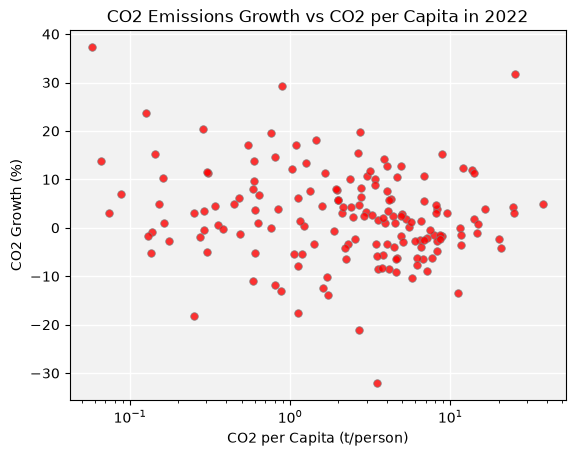

In [ ]:
ax = df_co2_2022_labeled.plot.scatter(
    x="co2_per_capita",
    y="co2_growth_prct",
    title="CO2 Emissions Growth vs CO2 per Capita in 2022",
    logx=True,
    grid=True,
    xlabel="CO2 per Capita (t/person)",
    ylabel="CO2 Growth (%)",
    marker="o",  # shape of the points
    c="red",  # color of the points
    s=30,  # size of the points
    edgecolor="grey",  # edge color of the points
    linewidth=0.6,  # edge line width of the points
    alpha=0.8,  # transparency of the points
)

ax.figure.set_facecolor("white")  # the whole figure (outside the axes)
ax.set_facecolor("#f2f2f2")  # the plotting area (inside the axes)

ax.grid(color="white", linewidth=1)
ax.set_axisbelow(True)

plt.show()

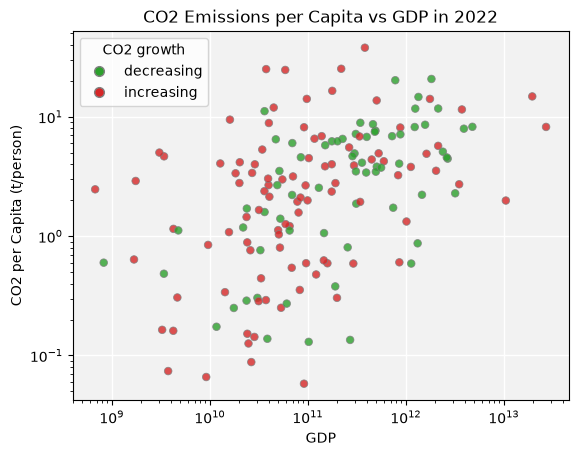

In [ ]:
from matplotlib.lines import Line2D

# One color per co2_growth_label, used for both the points and the legend
label_colors = {"decreasing": "tab:green", "increasing": "tab:red"}

ax = df_co2_2022_labeled.plot.scatter(
    x="gdp",
    y="co2_per_capita",
    title="CO2 Emissions per Capita vs GDP in 2022",
    logx=True,
    logy=True,
    grid=True,
    xlabel="GDP",
    ylabel="CO2 per Capita (t/person)",
    marker="o",  # shape of the points
    c=df_co2_2022_labeled["co2_growth_label"].map(label_colors),  # color of the points
    s=30,  # size of the points
    edgecolor="grey",  # edge color of the points
    linewidth=0.6,  # edge line width of the points
    alpha=0.8,  # transparency of the points
)

# Legend: one marker per label, drawn in the same color as the points
legend_handles = [
    Line2D(
        [],
        [],
        marker="o",
        linestyle="",
        markerfacecolor=color,
        markeredgecolor="grey",
        markersize=7,
        label=label,
    )
    for label, color in label_colors.items()
]
ax.legend(handles=legend_handles, title="CO2 growth")

ax.figure.set_facecolor("white")  # the whole figure (outside the axes)
ax.set_facecolor("#f2f2f2")  # the plotting area (inside the axes)

ax.grid(color="white", linewidth=1)
ax.set_axisbelow(True)

plt.show()

## 6. Build a KNN model

### 6.1 Define a problem:

Predict co2 emission growth is increasing or decreasing for each country based on its gdp and co2 emission data per person in that year.

Input:

- gdp
- co2_per_capita

Output:

- co2_growth_target: increasing (`target = 1`), decreasing (`target = 0`)

In [ ]:
df_co2_2022_labeled.head(10)

,country,year,population,gdp,co2,co2_per_capita,co2_growth_prct,co2_growth_target,co2_growth_label
1,Afghanistan,2022,40578847.0,5.330347e+10,10.170,0.251,3.050,1,increasing
2,Albania,2022,2827614.0,3.617101e+10,4.498,1.591,-12.434,0,decreasing
3,Algeria,2022,45477391.0,5.958201e+11,192.779,4.239,5.901,1,increasing
4,Angola,2022,35635028.0,1.583462e+11,21.089,0.592,9.732,1,increasing
5,Argentina,2022,45407904.0,8.549144e+11,183.768,4.047,-3.380,0,decreasing
6,Armenia,2022,2880880.0,3.972173e+10,7.699,2.672,4.735,1,increasing
7,Australia,2022,26200987.0,1.344251e+12,384.078,14.659,-1.131,0,decreasing
8,Austria,2022,9064678.0,3.988154e+11,61.454,6.780,-6.536,0,decreasing
9,Azerbaijan,2022,10295307.0,1.753706e+11,41.175,3.999,7.506,1,increasing
10,Bahrain,2022,1533460.0,5.876976e+10,37.827,24.668,4.306,1,increasing


In [ ]:
df_model_data = df_co2_2022_labeled.copy().loc[
    :, ["gdp", "co2_per_capita", "co2_growth_target"]
]

In [ ]:
df_model_data.head()

,gdp,co2_per_capita,co2_growth_target
1,5.330347e+10,0.251,1
2,3.617101e+10,1.591,0
3,5.958201e+11,4.239,1
4,1.583462e+11,0.592,1
5,8.549144e+11,4.047,0


### 6.2 Split dataset into Training and Testing

`train_test_split`: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html

In [ ]:
from sklearn.model_selection import train_test_split

X = df_model_data.loc[:, ["gdp", "co2_per_capita"]]
y = df_model_data["co2_growth_target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state=0)

In [ ]:
### Train-Test Split Summary
print("### Train-Test Split Summary")
print(f"Overall dataset shape: {X.shape}")
print(
    f"Training set shape: {X_train.shape}, percentage: {X_train.shape[0] / X.shape[0]:.2%}"
)
print(f"Test set shape: {X_test.shape}, percentage: {X_test.shape[0] / X.shape[0]:.2%}")

### Train-Test Split Summary
Overall dataset shape: (164, 2)
Training set shape: (123, 2), percentage: 75.00%
Test set shape: (41, 2), percentage: 25.00%


### 6.3 Build the KNN classifier

`KNeighborsClassifier`: https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html

In [ ]:
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier

estimator = KNeighborsClassifier(
    n_neighbors=9,
    weights="uniform",  # or "distance"
    algorithm="auto",  # or "ball_tree", "kd_tree", "brute"
)

estimator.fit(X_train, y_train)
y_pred = estimator.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy * 100:.2f}%")

Accuracy: 63.41%


In [ ]:
y_pred_df = pd.DataFrame(
    {"y_test": y_test, "y_pred": y_pred, "correct": y_test == y_pred}
)

In [ ]:
y_pred_df.head(10)
# y_pred_df.loc[y_pred_df["correct"]].shape[0] * 100/ y_pred_df.shape[0]

,y_test,y_pred,correct
76,0,1,False
106,0,0,True
69,1,1,True
100,1,1,True
23,1,1,True
133,0,1,False
71,1,0,False
151,0,0,True
78,1,0,False
105,1,1,True


### 6.4 Model's Hyper-parameters tuning

In [ ]:
metrics = pd.DataFrame(
    {
        "n_neighbors": [1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23],
        "uniform_accuracy": [None] * 12,
        "distance_accuracy": [None] * 12,
    }
)
metrics.head()

,n_neighbors,uniform_accuracy,distance_accuracy
0,1,None,None
1,3,None,None
2,5,None,None
3,7,None,None
4,9,None,None


In [ ]:
for weights in ["uniform", "distance"]:
    print(f"##### Training KNN with weights={weights}")
    for i, n_neighbors in enumerate(metrics["n_neighbors"]):
        estimator = KNeighborsClassifier(
            n_neighbors=n_neighbors,
            weights=weights,  # or "distance"
            algorithm="auto",  # or "ball_tree", "kd_tree", "brute"
        )

        estimator.fit(X_train, y_train)
        y_pred = estimator.predict(X_test)
        accuracy = accuracy_score(y_test, y_pred)
        if weights == "uniform":
            metrics.loc[i, "uniform_accuracy"] = accuracy
        else:
            metrics.loc[i, "distance_accuracy"] = accuracy
        print(
            f"Training KNN with n_neighbors={n_neighbors} and weights={weights}, accuracy={accuracy}"
        )


##### Training KNN with weights=uniform
Training KNN with n_neighbors=1 and weights=uniform, accuracy=0.43902439024390244
Training KNN with n_neighbors=3 and weights=uniform, accuracy=0.4634146341463415
Training KNN with n_neighbors=5 and weights=uniform, accuracy=0.5121951219512195
Training KNN with n_neighbors=7 and weights=uniform, accuracy=0.5853658536585366
Training KNN with n_neighbors=9 and weights=uniform, accuracy=0.6341463414634146
Training KNN with n_neighbors=11 and weights=uniform, accuracy=0.6585365853658537
Training KNN with n_neighbors=13 and weights=uniform, accuracy=0.6585365853658537
Training KNN with n_neighbors=15 and weights=uniform, accuracy=0.6829268292682927
Training KNN with n_neighbors=17 and weights=uniform, accuracy=0.6829268292682927
Training KNN with n_neighbors=19 and weights=uniform, accuracy=0.6829268292682927
Training KNN with n_neighbors=21 and weights=uniform, accuracy=0.6585365853658537
Training KNN with n_neighbors=23 and weights=uniform, accuracy

In [ ]:
metrics

,n_neighbors,uniform_accuracy,distance_accuracy
0,1,0.439024,0.439024
1,3,0.463415,0.414634
2,5,0.512195,0.414634
3,7,0.585366,0.439024
4,9,0.634146,0.414634
5,11,0.658537,0.439024
6,13,0.658537,0.439024
7,15,0.682927,0.487805
8,17,0.682927,0.512195
9,19,0.682927,0.512195


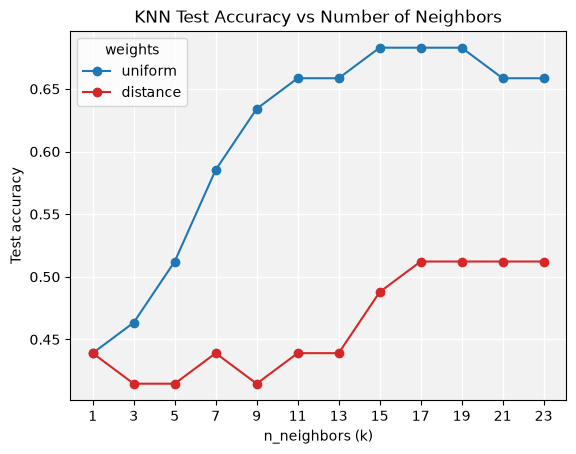

In [ ]:
fig, ax = plt.subplots()

# The accuracy columns started as None, so convert them to numbers before plotting
ax.plot(
    metrics["n_neighbors"],
    metrics["uniform_accuracy"].astype(float),
    marker="o",
    color="tab:blue",
    label="uniform",
)
ax.plot(
    metrics["n_neighbors"],
    metrics["distance_accuracy"].astype(float),
    marker="o",
    color="tab:red",
    label="distance",
)

ax.set_title("KNN Test Accuracy vs Number of Neighbors")
ax.set_xlabel("n_neighbors (k)")
ax.set_ylabel("Test accuracy")
ax.set_xticks(metrics["n_neighbors"])
ax.legend(title="weights")

ax.figure.set_facecolor("white")  # the whole figure (outside the axes)
ax.set_facecolor("#f2f2f2")  # the plotting area (inside the axes)

ax.grid(color="white", linewidth=1)
ax.set_axisbelow(True)

plt.show()

### 6.5 Why applying scaler to the input dataset?

In [ ]:
metrics_scaling = pd.DataFrame(
    {
        "n_neighbors": [1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23],
        "without_scaling": [None] * 12,
        "with_scaling": [None] * 12,
    }
)
metrics_scaling.head()

,n_neighbors,without_scaling,with_scaling
0,1,None,None
1,3,None,None
2,5,None,None
3,7,None,None
4,9,None,None


In [ ]:
# apply StandardScaler to the features before fitting the KNN model

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
for model in ["without_scaling", "with_scaling"]:
    print(f"##### Training KNN with model={model}")
    for i, n_neighbors in enumerate(metrics_scaling["n_neighbors"]):
        estimator = KNeighborsClassifier(
            n_neighbors=n_neighbors,
            weights="uniform",
            algorithm="auto",
        )

        if model == "with_scaling":
            estimator.fit(X_train_scaled, y_train)
            y_pred = estimator.predict(X_test_scaled)
        else:
            estimator.fit(X_train, y_train)
            y_pred = estimator.predict(X_test)

        accuracy = accuracy_score(y_test, y_pred)
        if model == "without_scaling":
            metrics_scaling.loc[i, "without_scaling"] = accuracy
        else:
            metrics_scaling.loc[i, "with_scaling"] = accuracy
        print(
            f"Training KNN with n_neighbors={n_neighbors} and model={model}, accuracy={accuracy}"
        )

##### Training KNN with model=without_scaling
Training KNN with n_neighbors=1 and model=without_scaling, accuracy=0.43902439024390244
Training KNN with n_neighbors=3 and model=without_scaling, accuracy=0.4634146341463415
Training KNN with n_neighbors=5 and model=without_scaling, accuracy=0.5121951219512195
Training KNN with n_neighbors=7 and model=without_scaling, accuracy=0.5853658536585366
Training KNN with n_neighbors=9 and model=without_scaling, accuracy=0.6341463414634146
Training KNN with n_neighbors=11 and model=without_scaling, accuracy=0.6585365853658537
Training KNN with n_neighbors=13 and model=without_scaling, accuracy=0.6585365853658537
Training KNN with n_neighbors=15 and model=without_scaling, accuracy=0.6829268292682927
Training KNN with n_neighbors=17 and model=without_scaling, accuracy=0.6829268292682927
Training KNN with n_neighbors=19 and model=without_scaling, accuracy=0.6829268292682927
Training KNN with n_neighbors=21 and model=without_scaling, accuracy=0.6585365

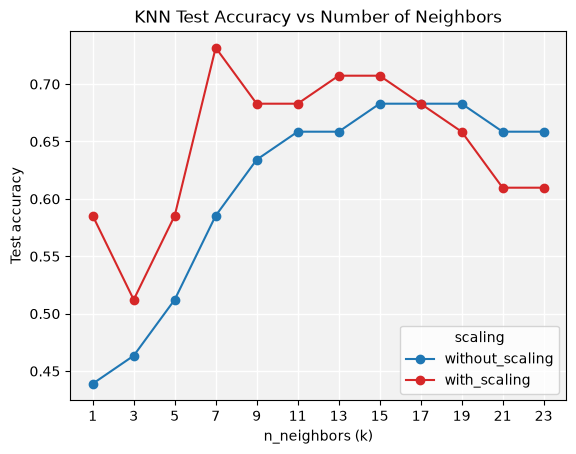

In [ ]:
fig, ax = plt.subplots()

# The accuracy columns started as None, so convert them to numbers before plotting
ax.plot(
    metrics_scaling["n_neighbors"],
    metrics_scaling["without_scaling"].astype(float),
    marker="o",
    color="tab:blue",
    label="without_scaling",
)
ax.plot(
    metrics_scaling["n_neighbors"],
    metrics_scaling["with_scaling"].astype(float),
    marker="o",
    color="tab:red",
    label="with_scaling",
)

ax.set_title("KNN Test Accuracy vs Number of Neighbors")
ax.set_xlabel("n_neighbors (k)")
ax.set_ylabel("Test accuracy")
ax.set_xticks(metrics_scaling["n_neighbors"])
ax.legend(title="scaling")

ax.figure.set_facecolor("white")  # the whole figure (outside the axes)
ax.set_facecolor("#f2f2f2")  # the plotting area (inside the axes)

ax.grid(color="white", linewidth=1)
ax.set_axisbelow(True)

plt.show()

## 7. Save the cleaned datasets into file

In [ ]:
df_co2_2022_labeled.to_csv("../../data/df_co2_2022_labeled.csv", index=False)